# Инструменты ядра daslang 0.12

Таблицы, изображения и WAV, экспорт автономной программы, пакеты, тесты, покрытие, LSP-справка и пошаговая отладка через настоящий DAP.

Тесты, покрытие и отладка используют отдельный снимок root-глобальных значений. Они не изменяют основную сессию. Файловые и сетевые эффекты остаются реальными. Требуется соответствующий SDK/runtime bundle; после обновления перезапустите ядро.

In [1]:
var value=42
struct Score {name:string; points:int}
var row:Score
row.name="Alice"
row.points=42
var rows:array<Score>
rows |> push(row)
def square(x:int):int {return x*x}
var sequence:array<int>
for (i in range(200)) {sequence |> push(i)}

In [2]:
%vars

Name,Type,Binding,Preview
value,int,var,42
row,Score,var,2 fields
rows,array<Score>,var,[2 fields] · 1 elements
sequence,array<int>,var,"[0, 1, 2, …] · 200 elements"


In [3]:
%view rows

#,name,points
0,"""Alice""",42


In [4]:
%view row --depth 3

row : Score
{
  "type": "Score",
  "kind": "struct",
  "fields": [
    {
      "name": "name",
      "value": {
        "type": "string",
        "kind": "scalar",
        "size": 5,
        "value": "Alice"
      }
    },
    {
      "name": "points",
      "value": {
        "type": "int",
        "kind": "scalar",
        "value": 42
      }
    }
  ],
  "size": 2
}

In [5]:
%view sequence --start 100 --count 10

sequence : array<int>
{
  "type": "array<int>",
  "kind": "array",
  "size": 200,
  "start": 100,
  "items": [
    {
      "index": 100,
      "value": {
        "type": "int",
        "kind": "scalar",
        "value": 100
      }
    },
    {
      "index": 101,
      "value": {
        "type": "int",
        "kind": "scalar",
        "value": 101
      }
    },
    {
      "index": 102,
      "value": {
        "type": "int",
        "kind": "scalar",
        "value": 102
      }
    },
    {
      "index": 103,
      "value": {
        "type": "int",
        "kind": "scalar",
        "value": 103
      }
    },
    {
      "index": 104,
      "value": {
        "type": "int",
        "kind": "scalar",
        "value": 104
      }
    },
    {
      "index": 105,
      "value": {
        "type": "int",
        "kind": "scalar",
        "value": 105
      }
    },
    {
      "index": 106,
      "value": {
        "type": "int",
        "kind": "scalar",
        "value": 106
      }
    },
    {
      "index": 107,
      "value": {
        "type": "int",
        "kind": "scalar",
        "value": 107
      }
    },
    {
      "index": 108,
      "value": {
        "type": "int",
        "kind": "scalar",
        "value": 108
      }
    },
    {
      "index": 109,
      "value": {
        "type": "int",
        "kind": "scalar",
        "value": 109
      }
    }
  ]
}

#,name,points
0,Alice,42


**Снимок результата**, сохранённый в ноутбуке.

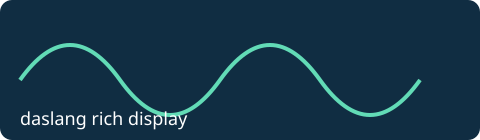

C:\Users\sanya\Documents\Codex\2026-10-11\jupyter\work\macro-inspection-pr\examples\assets\notebook-tools.wav

In [6]:
display(rows)
display_markdown("**Снимок результата**, сохранённый в ноутбуке.")
display_image("assets/notebook-tools.svg")
display_audio("assets/notebook-tools.wav")

In [7]:
%%export tools-export.das
verify(square(value)==1764)
print("{value}\n")

Exported C:\Users\sanya\Documents\Codex\2026-10-11\jupyter\work\macro-inspection-pr\examples\tools-export.das

Созданный `tools-export.das` можно запустить соответствующим `daslang.exe`: он восстановит сохранённые значения и выполнит только указанное тело `main`.

In [8]:
%pkg list

No packages installed (no lock file found)


In [9]:
%modules

Registered native modules:
$, ast_core, dasbind, debugapi, fio_core, jit, math, network_core, rtti_core, strings
Project modules:


In [10]:
%%test
assert(value==42)
verify(square(3)==9)
value=99

PASS: isolated notebook assertions


In [11]:
value

42

In [12]:
%%coverage --output tools-demo.lcov
if (value==42) {
    value+=1
} else {
    value=0
}


Notebook lines: 3/5 covered (60.0%)
Branches: 1/2 covered
In[1]:2      2  struct Score {name:string; points:int}
In[1]:8      0  def square(x:int):int {return x*x}
cell:2      1  if (value==42) {
cell:3      1      value+=1
cell:5      0      value=0
LCOV: C:\Users\sanya\Documents\Codex\2026-10-11\jupyter\work\macro-inspection-pr\examples\tools-demo.lcov

In [13]:
%%check
square(value)

{
  "ok": true,
  "diagnostics": [
    {
      "range": {
        "start": {
          "line": 41,
          "character": 4
        },
        "end": {
          "line": 41,
          "character": 10
        }
      },
      "severity": 3,
      "code": "STYLE042",
      "source": "daslang-lint",
      "message": "function 'square' body is a single 'return'; write it as an expression body - 'def square(...) => EXPR'",
      "cell": "In[1]",
      "line": 8
    }
  ]
}

In [14]:
%definition square(value)

{
  "ok": true,
  "message": "",
  "locations": [
    {
      "path": "<notebook>",
      "range": {
        "start": {
          "line": 41,
          "character": 4
        },
        "end": {
          "line": 41,
          "character": 10
        }
      },
      "cell": "In[1]",
      "line": 8
    }
  ]
}

In [15]:
%lsp on

Compiler-backed hover on

После `%lsp on` попробуйте Shift+Tab на `square(value)` в редакторе. Используется compiler-backed hover SDK; обычное автодополнение продолжает работать.

In [16]:
%%debug --break 2
value+=1
print("{value}\n")

{
  "breakpoints": {
    "breakpoints": [
      {
        "id": 1,
        "verified": true,
        "source": {
          "name": "",
          "path": "C:\\Users\\sanya\\Documents\\Codex\\2026-10-11\\jupyter\\work\\macro-inspection-pr\\examples\\.djnb-bak6zm56.das"
        },
        "line": 68,
        "message": ""
      }
    ]
  },
  "event": {
    "type": "event",
    "event": "stopped",
    "body": {
      "reason": "breakpoint",
      "text": null,
      "threadId": 4,
      "allThreadsStopped": false,
      "hitBreakpointIds": [
        1
      ]
    }
  }
}

In [17]:
%debug stack

{
  "stackFrames": [
    {
      "id": 4000,
      "name": "def djnb_cell",
      "source": {
        "name": "C:\\Users\\sanya\\Documents\\Codex\\2026-10-11\\jupyter\\work\\macro-inspection-pr\\examples\\.djnb-bak6zm56.das",
        "path": "C:\\Users\\sanya\\Documents\\Codex\\2026-10-11\\jupyter\\work\\macro-inspection-pr\\examples\\.djnb-bak6zm56.das"
      },
      "line": 68,
      "column": 1,
      "cell": "cell",
      "cellLine": 2
    },
    {
      "id": 4001,
      "name": "def main",
      "source": {
        "name": "C:\\Users\\sanya\\Documents\\Codex\\2026-10-11\\jupyter\\work\\macro-inspection-pr\\examples\\.djnb-bak6zm56.das",
        "path": "C:\\Users\\sanya\\Documents\\Codex\\2026-10-11\\jupyter\\work\\macro-inspection-pr\\examples\\.djnb-bak6zm56.das"
      },
      "line": 82,
      "column": 1
    }
  ],
  "totalFrames": 2
}

In [18]:
%debug eval value

{
  "result": "42",
  "type": "int",
  "variablesReference": 0,
  "indexedVariables": 0
}

In [19]:
%debug next

{
  "type": "event",
  "event": "stopped",
  "body": {
    "reason": "step",
    "text": null,
    "threadId": 4,
    "allThreadsStopped": false,
    "hitBreakpointIds": null
  }
}

In [20]:
%debug eval value

{
  "result": "43",
  "type": "int",
  "variablesReference": 0,
  "indexedVariables": 0
}

In [21]:
%debug continue

{
  "event": "terminated",
  "body": {
    "output": "dap: install debug agent\r\n43\r\n"
  }
}

In [22]:
value

42

В debug-процессе значение стало 43, а в основной сессии осталось 42. Отладчик управляется командами ячеек; графическая панель JupyterLab здесь не используется.

In [23]:
%lsp off

Compiler-backed hover off

In [24]:
%reset